# Starbucks Rewards — exploring the data

This notebook introduces the three local files, checks their quality, and follows a customer's activity through time. Start here before designing PostgreSQL tables or campaign metrics.

**Questions we will answer**
- What does one row in each file mean, and how do the files connect?
- What information is missing or needs interpretation?
- How are purchases and offer interactions recorded?
- What decisions do we need to make before calculating a funnel?

Run the cells from top to bottom in a Python notebook environment with `pandas` installed. The file lookup supports opening this notebook from the project folder or a `notebooks` subfolder. All transformations stay in memory.

The examples and findings below come from the local files. This is simulated Starbucks Rewards data used in the Udacity capstone.


## 1. Load the three files

Each file is **JSON Lines**. Each line contains one JSON object, which becomes one table row. `lines=True` tells pandas how to read this format.

| File | One row means | Main identifier |
|---|---|---|
| `profile.json` | One customer | `id` |
| `portfolio.json` | One offer definition | `id` |
| `transcript.json` | One recorded activity | Customer in `person`, with offer details inside `value` when applicable |


In [1]:
from pathlib import Path
import html
import json
import platform

import pandas as pd

pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 90)
pd.set_option('display.width', 140)

required_files = ('profile.json', 'portfolio.json', 'transcript.json')
search_folders = (Path.cwd(), Path.cwd().parent)
DATA_DIR = next(
    (folder for folder in search_folders if all((folder / name).is_file() for name in required_files)),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError('Place the three JSON files beside this notebook, then run it from the project folder.')

profile_raw = pd.read_json(DATA_DIR / 'profile.json', lines=True)
portfolio_raw = pd.read_json(DATA_DIR / 'portfolio.json', lines=True)
transcript_raw = pd.read_json(DATA_DIR / 'transcript.json', lines=True)

print(f'Python {platform.python_version()} | pandas {pd.__version__}')
print(f'Data folder: {DATA_DIR}')
display(pd.DataFrame([
    {'file': name, 'rows': len(frame), 'columns': len(frame.columns)}
    for name, frame in zip(required_files, (profile_raw, portfolio_raw, transcript_raw))
]))


Python 3.12.14 | pandas 3.0.1
Data folder: E:\AI matirial\loyalty analysis


,file,rows,columns
0,profile.json,17000,5
1,portfolio.json,10,6
2,transcript.json,306534,4


In [2]:
print('CUSTOMERS — first three rows')
display(profile_raw.head(3))
print('OFFERS — all ten definitions')
display(portfolio_raw)
print('EVENTS — first five rows')
display(transcript_raw.head())


CUSTOMERS — first three rows


,gender,age,id,became_member_on,income
0,NaN,118,68be06ca386d4c31939f3a4f0e3dd783,20170212,NaN
1,F,55,0610b486422d4921ae7d2bf64640c50b,20170715,112000.0
2,NaN,118,38fe809add3b4fcf9315a9694bb96ff5,20180712,NaN


OFFERS — all ten definitions


,reward,channels,difficulty,duration,offer_type,id
0,10,"[email, mobile, social]",10,7,bogo,ae264e3637204a6fb9bb56bc8210ddfd
1,10,"[web, email, mobile, social]",10,5,bogo,4d5c57ea9a6940dd891ad53e9dbe8da0
2,0,"[web, email, mobile]",0,4,informational,3f207df678b143eea3cee63160fa8bed
3,5,"[web, email, mobile]",5,7,bogo,9b98b8c7a33c4b65b9aebfe6a799e6d9
4,5,"[web, email]",20,10,discount,0b1e1539f2cc45b7b9fa7c272da2e1d7
5,3,"[web, email, mobile, social]",7,7,discount,2298d6c36e964ae4a3e7e9706d1fb8c2
6,2,"[web, email, mobile, social]",10,10,discount,fafdcd668e3743c1bb461111dcafc2a4
7,0,"[email, mobile, social]",0,3,informational,5a8bc65990b245e5a138643cd4eb9837
8,5,"[web, email, mobile, social]",5,5,bogo,f19421c1d4aa40978ebb69ca19b0e20d
9,2,"[web, email, mobile]",10,7,discount,2906b810c7d4411798c6938adc9daaa5


EVENTS — first five rows


,person,event,value,time
0,78afa995795e4d85b5d9ceeca43f5fef,offer received,{'offer id': '9b98b8c7a33c4b65b9aebfe6a799e6d9'},0
1,a03223e636434f42ac4c3df47e8bac43,offer received,{'offer id': '0b1e1539f2cc45b7b9fa7c272da2e1d7'},0
2,e2127556f4f64592b11af22de27a7932,offer received,{'offer id': '2906b810c7d4411798c6938adc9daaa5'},0
3,8ec6ce2a7e7949b1bf142def7d0e0586,offer received,{'offer id': 'fafdcd668e3743c1bb461111dcafc2a4'},0
4,68617ca6246f4fbc85e91a2a49552598,offer received,{'offer id': '4d5c57ea9a6940dd891ad53e9dbe8da0'},0


## 2. Understand the columns

`difficulty` is the offer's spending requirement. `duration` is measured in **days**. Event `time` is measured in **hours from the start of the observation period**. Keep these units explicit when matching a delivery to its expiry.

`channels` is a list of channels associated with an offer. A view event has no channel field, so channel comparisons will describe the distribution combinations attached to offers.

The event payload in `value` changes with the event type. We will inspect its actual keys before extracting fields.


In [3]:
column_profiles = []
for table_name, frame in (
    ('customers', profile_raw), ('offers', portfolio_raw), ('events', transcript_raw)
):
    for column in frame.columns:
        column_profiles.append({
            'table': table_name,
            'column': column,
            'pandas_type': str(frame[column].dtype),
            'missing_rows': int(frame[column].isna().sum()),
            'missing_pct': round(frame[column].isna().mean() * 100, 2),
        })
display(pd.DataFrame(column_profiles))

payload_shapes = (
    transcript_raw.assign(payload_keys=transcript_raw['value'].map(lambda value: ', '.join(sorted(value))))
    .groupby(['event', 'payload_keys'])
    .size()
    .reset_index(name='rows')
)
display(payload_shapes)
print('One actual payload for each event type:')
display(transcript_raw.groupby('event', sort=True).head(1)[['event', 'value']])


,table,column,pandas_type,missing_rows,missing_pct
0,customers,gender,str,2175,12.79
1,customers,age,int64,0,0.00
2,customers,id,str,0,0.00
3,customers,became_member_on,int64,0,0.00
4,customers,income,float64,2175,12.79
5,offers,reward,int64,0,0.00
6,offers,channels,object,0,0.00
7,offers,difficulty,int64,0,0.00
8,offers,duration,int64,0,0.00
9,offers,offer_type,str,0,0.00


,event,payload_keys,rows
0,offer completed,"offer_id, reward",33579
1,offer received,offer id,76277
2,offer viewed,offer id,57725
3,transaction,amount,138953


One actual payload for each event type:


,event,value
0,offer received,{'offer id': '9b98b8c7a33c4b65b9aebfe6a799e6d9'}
12650,offer viewed,{'offer id': 'f19421c1d4aa40978ebb69ca19b0e20d'}
12654,transaction,{'amount': 0.8300000000000001}
12658,offer completed,"{'offer_id': '2906b810c7d4411798c6938adc9daaa5', 'reward': 2}"


## 3. Inspect customer demographics

The source contains customers recorded as age `118`. We first check how this value overlaps with missing income and gender. For exploratory demographic summaries, we treat age 118 as an unknown age and retain every customer. The original age remains available in `age_raw`.

The membership field is a calendar date. The activity log provides relative hours, so a calendar date for an event would require a known observation start date.


In [4]:
age_118 = profile_raw['age'].eq(118)
missing_demographics = profile_raw['gender'].isna() & profile_raw['income'].isna()
display(pd.crosstab(
    age_118.rename('age_is_118'),
    missing_demographics.rename('gender_and_income_missing'),
))

customers = profile_raw.rename(columns={'id': 'customer_id', 'age': 'age_raw'}).copy()
customers['age'] = customers['age_raw'].mask(customers['age_raw'].eq(118)).astype('Int64')
customers['member_since'] = pd.to_datetime(
    customers['became_member_on'].astype(str), format='%Y%m%d', errors='coerce'
)
customers['gender_group'] = customers['gender'].fillna('Unknown')

print('Numeric summaries after the exploratory age treatment:')
display(customers[['age', 'income']].describe().round(2))
display(customers['gender_group'].value_counts(dropna=False).rename_axis('gender').to_frame('customers'))
print(f"Membership dates: {customers['member_since'].min().date()} through {customers['member_since'].max().date()}")
print(f"Unparseable membership dates: {customers['member_since'].isna().sum():,}")


gender_and_income_missing,False,True
age_is_118,,
False,14825,0
True,0,2175


Numeric summaries after the exploratory age treatment:


,age,income
count,14825.0,14825.00
mean,54.39,65404.99
std,17.38,21598.30
min,18.0,30000.00
25%,42.0,49000.00
50%,55.0,64000.00
75%,66.0,80000.00
max,101.0,120000.00


,customers
gender,
M,8484
F,6129
Unknown,2175
O,212


Membership dates: 2013-07-29 through 2018-07-26
Unparseable membership dates: 0


## 4. Inspect offer types and channel combinations

A BOGO or discount offer can produce an `offer completed` event. Informational offers advertise something and should be explored through exposure, views, and purchase activity.

There are ten offer definitions, each reusable across customers and delivery times. We use short labels O01–O10 for readable examples, while keeping the source IDs for joins.


In [5]:
offers = portfolio_raw.rename(columns={'id': 'offer_id'}).copy()
offers['offer_label'] = [f'O{number:02d}' for number in range(1, len(offers) + 1)]
offers['duration_hours'] = offers['duration'] * 24
offers['channel_combination'] = offers['channels'].map(lambda values: ', '.join(sorted(values)))

display(offers[[
    'offer_label', 'offer_id', 'offer_type', 'difficulty', 'reward',
    'duration', 'duration_hours', 'channel_combination'
]])
display(offers.groupby(['offer_type', 'channel_combination']).size().reset_index(name='offer_definitions'))

channel_definitions = offers[['offer_id', 'channels']].explode('channels')
display(channel_definitions['channels'].value_counts().rename_axis('channel').to_frame('offer_definitions'))
print('An offer with several channels contributes once to each channel count above.')


,offer_label,offer_id,offer_type,difficulty,reward,duration,duration_hours,channel_combination
0,O01,ae264e3637204a6fb9bb56bc8210ddfd,bogo,10,10,7,168,"email, mobile, social"
1,O02,4d5c57ea9a6940dd891ad53e9dbe8da0,bogo,10,10,5,120,"email, mobile, social, web"
2,O03,3f207df678b143eea3cee63160fa8bed,informational,0,0,4,96,"email, mobile, web"
3,O04,9b98b8c7a33c4b65b9aebfe6a799e6d9,bogo,5,5,7,168,"email, mobile, web"
4,O05,0b1e1539f2cc45b7b9fa7c272da2e1d7,discount,20,5,10,240,"email, web"
5,O06,2298d6c36e964ae4a3e7e9706d1fb8c2,discount,7,3,7,168,"email, mobile, social, web"
6,O07,fafdcd668e3743c1bb461111dcafc2a4,discount,10,2,10,240,"email, mobile, social, web"
7,O08,5a8bc65990b245e5a138643cd4eb9837,informational,0,0,3,72,"email, mobile, social"
8,O09,f19421c1d4aa40978ebb69ca19b0e20d,bogo,5,5,5,120,"email, mobile, social, web"
9,O10,2906b810c7d4411798c6938adc9daaa5,discount,10,2,7,168,"email, mobile, web"


,offer_type,channel_combination,offer_definitions
0,bogo,"email, mobile, social",1
1,bogo,"email, mobile, social, web",2
2,bogo,"email, mobile, web",1
3,discount,"email, mobile, social, web",2
4,discount,"email, mobile, web",1
5,discount,"email, web",1
6,informational,"email, mobile, social",1
7,informational,"email, mobile, web",1


,offer_definitions
channel,
email,10
mobile,9
web,8
social,6


An offer with several channels contributes once to each channel count above.


## 5. Extract fields from the activity log

Received and viewed events use the payload key `offer id`. Completed events use `offer_id`. We normalize both into one column.

Purchase amounts and completion rewards get separate columns. Their missing values are expected on other event types. `source_row` records the event position, excluding blank lines, for tracing examples.


In [6]:
events = transcript_raw.rename(columns={'person': 'customer_id', 'time': 'time_hours'}).copy()
events.insert(0, 'source_row', range(1, len(events) + 1))
events['offer_id'] = events['value'].map(lambda value: value.get('offer_id', value.get('offer id')))
events['transaction_amount'] = pd.to_numeric(events['value'].map(lambda value: value.get('amount')), errors='coerce')
events['completion_reward'] = pd.to_numeric(events['value'].map(lambda value: value.get('reward')), errors='coerce')
events['event_day'] = events['time_hours'] // 24

display(events[['source_row', 'customer_id', 'event', 'time_hours', 'event_day', 'offer_id', 'transaction_amount', 'completion_reward']].head())
event_counts = events['event'].value_counts().rename_axis('event').to_frame('rows')
event_counts['pct_of_events'] = (event_counts['rows'] / len(events) * 100).round(2)
display(event_counts)
display(events.groupby('event').agg(
    rows=('source_row', 'size'),
    distinct_customers=('customer_id', 'nunique'),
    distinct_offers=('offer_id', 'nunique'),
))


,source_row,customer_id,event,time_hours,event_day,offer_id,transaction_amount,completion_reward
0,1,78afa995795e4d85b5d9ceeca43f5fef,offer received,0,0,9b98b8c7a33c4b65b9aebfe6a799e6d9,NaN,NaN
1,2,a03223e636434f42ac4c3df47e8bac43,offer received,0,0,0b1e1539f2cc45b7b9fa7c272da2e1d7,NaN,NaN
2,3,e2127556f4f64592b11af22de27a7932,offer received,0,0,2906b810c7d4411798c6938adc9daaa5,NaN,NaN
3,4,8ec6ce2a7e7949b1bf142def7d0e0586,offer received,0,0,fafdcd668e3743c1bb461111dcafc2a4,NaN,NaN
4,5,68617ca6246f4fbc85e91a2a49552598,offer received,0,0,4d5c57ea9a6940dd891ad53e9dbe8da0,NaN,NaN


,rows,pct_of_events
event,,
transaction,138953,45.33
offer received,76277,24.88
offer viewed,57725,18.83
offer completed,33579,10.95


,rows,distinct_customers,distinct_offers
event,,,
offer completed,33579,12774,8
offer received,76277,16994,10
offer viewed,57725,16834,10
transaction,138953,16578,0


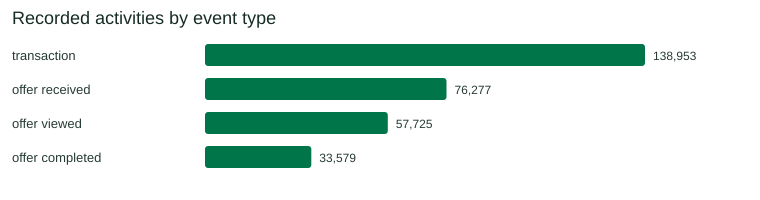

In [7]:
def show_bar_chart(values, title, color='#00754a'):
    """Display a small SVG chart without additional plotting dependencies."""
    width, label_width, plot_width = 760, 205, 440
    row_height, top = 34, 44
    height = top + len(values) * row_height + 20
    maximum = max(float(values.max()), 1)
    elements = [
        f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" role="img" aria-label="{html.escape(title)}">',
        '<rect width="100%" height="100%" fill="white"/>',
        f'<text x="12" y="24" font-size="18" font-family="Arial" fill="#172c24">{html.escape(title)}</text>',
    ]
    for position, (label, value) in enumerate(values.items()):
        y = top + position * row_height
        bar_width = float(value) / maximum * plot_width
        elements.extend([
            f'<text x="12" y="{y + 16}" font-size="13" font-family="Arial" fill="#263b33">{html.escape(str(label))}</text>',
            f'<rect x="{label_width}" y="{y}" width="{bar_width:.1f}" height="22" rx="3" fill="{color}"/>',
            f'<text x="{label_width + bar_width + 8:.1f}" y="{y + 16}" font-size="12" font-family="Arial" fill="#263b33">{value:,.0f}</text>',
        ])
    elements.append('</svg>')
    display({'image/svg+xml': ''.join(elements)}, raw=True)

show_bar_chart(event_counts['rows'], 'Recorded activities by event type')


**How to read the activity counts**

Each bar counts event rows. A customer may receive several offers, view several times, and make many purchases. Dividing these totals can mix deliveries and repeated activities. Delivery-level funnel rates will require matching each event to a specific receipt.


## 6. Check data quality and relationships

We check unique customer and offer IDs, references between files, payload completeness, and exact repeated records. An exact repeated record can represent several legitimate activities with identical recorded fields. We retain those rows while investigating their meaning.


In [8]:
is_offer_event = events['event'].str.startswith('offer ')
is_transaction = events['event'].eq('transaction')
canonical_payload = transcript_raw['value'].map(lambda value: json.dumps(value, sort_keys=True))
duplicate_mask = transcript_raw.assign(value=canonical_payload).duplicated(keep=False)
extra_duplicate_mask = transcript_raw.assign(value=canonical_payload).duplicated()

quality_checks = pd.DataFrame([
    ('Missing customer IDs in profile', customers['customer_id'].isna().sum()),
    ('Duplicate customer IDs in profile', customers['customer_id'].duplicated().sum()),
    ('Missing offer IDs in portfolio', offers['offer_id'].isna().sum()),
    ('Duplicate offer IDs in portfolio', offers['offer_id'].duplicated().sum()),
    ('Events referencing an unknown customer', (~events['customer_id'].isin(customers['customer_id'])).sum()),
    ('Offer events missing an offer ID', (is_offer_event & events['offer_id'].isna()).sum()),
    ('Offer events referencing an unknown offer', (is_offer_event & ~events['offer_id'].isin(offers['offer_id'])).sum()),
    ('Transactions missing an amount', (is_transaction & events['transaction_amount'].isna()).sum()),
    ('Completed events missing a reward', (events['event'].eq('offer completed') & events['completion_reward'].isna()).sum()),
    ('Events missing a time', events['time_hours'].isna().sum()),
    ('Events with a negative time', events['time_hours'].lt(0).sum()),
    ('Exact repeated rows beyond the first occurrence', extra_duplicate_mask.sum()),
], columns=['check', 'rows'])
display(quality_checks)
print('Repeated records, including their first occurrences:')
display(events.loc[duplicate_mask, ['source_row', 'customer_id', 'event', 'time_hours', 'value']].head(10))
display(events.loc[extra_duplicate_mask, 'event'].value_counts().rename_axis('event').to_frame('extra_identical_rows'))


,check,rows
0,Missing customer IDs in profile,0
1,Duplicate customer IDs in profile,0
2,Missing offer IDs in portfolio,0
3,Duplicate offer IDs in portfolio,0
4,Events referencing an unknown customer,0
5,Offer events missing an offer ID,0
6,Offer events referencing an unknown offer,0
7,Transactions missing an amount,0
8,Completed events missing a reward,0
9,Events missing a time,0


Repeated records, including their first occurrences:


,source_row,customer_id,event,time_hours,value
66122,66123,3dde94fa581145cb9f206624f1a94d5a,offer completed,168,"{'offer_id': '2906b810c7d4411798c6938adc9daaa5', 'reward': 2}"
66123,66124,3dde94fa581145cb9f206624f1a94d5a,offer completed,168,"{'offer_id': '2906b810c7d4411798c6938adc9daaa5', 'reward': 2}"
66782,66783,e9fb6ed2cecb4980ba98c86abc9c91e3,offer completed,168,"{'offer_id': 'ae264e3637204a6fb9bb56bc8210ddfd', 'reward': 10}"
66783,66784,e9fb6ed2cecb4980ba98c86abc9c91e3,offer completed,168,"{'offer_id': 'ae264e3637204a6fb9bb56bc8210ddfd', 'reward': 10}"
67613,67614,a7dc060f6fc94ca7bf71fbb188187dca,offer completed,168,"{'offer_id': '9b98b8c7a33c4b65b9aebfe6a799e6d9', 'reward': 5}"
67614,67615,a7dc060f6fc94ca7bf71fbb188187dca,offer completed,168,"{'offer_id': '9b98b8c7a33c4b65b9aebfe6a799e6d9', 'reward': 5}"
68561,68562,30478a4c1e884a63a822aa87b833ed7a,offer completed,168,"{'offer_id': '2298d6c36e964ae4a3e7e9706d1fb8c2', 'reward': 3}"
68562,68563,30478a4c1e884a63a822aa87b833ed7a,offer completed,168,"{'offer_id': '2298d6c36e964ae4a3e7e9706d1fb8c2', 'reward': 3}"
69217,69218,84fb57a7fe8045a8bf6236738ee73a0f,offer completed,168,"{'offer_id': 'ae264e3637204a6fb9bb56bc8210ddfd', 'reward': 10}"
69218,69219,84fb57a7fe8045a8bf6236738ee73a0f,offer completed,168,"{'offer_id': 'ae264e3637204a6fb9bb56bc8210ddfd', 'reward': 10}"


,extra_identical_rows
event,
offer completed,397


## 7. Explore the observation timeline

Days below are numbered from zero. The last recorded event is the observed time boundary, which may precede the nominal end of data collection. Counts near that boundary need interpretation before retention or offer-expiry calculations.


First event hour: 0
Last event hour: 714
Distinct event timestamps: 120
First twelve recorded timestamps: [np.int64(0), np.int64(6), np.int64(12), np.int64(18), np.int64(24), np.int64(30), np.int64(36), np.int64(42), np.int64(48), np.int64(54), np.int64(60), np.int64(66)]
Gaps between consecutive recorded timestamps, in hours:


,occurrences
gap_hours,
6.0,119


event,offer completed,offer received,offer viewed,transaction
event_day,,,,
0,1014,12650,5474,3159
1,1025,0,2168,4006
2,848,0,1006,4190
3,655,0,549,4035
4,480,0,357,3814
5,358,0,229,3484
6,278,0,160,3235
7,1429,12669,5729,4211
8,1309,0,2098,4671


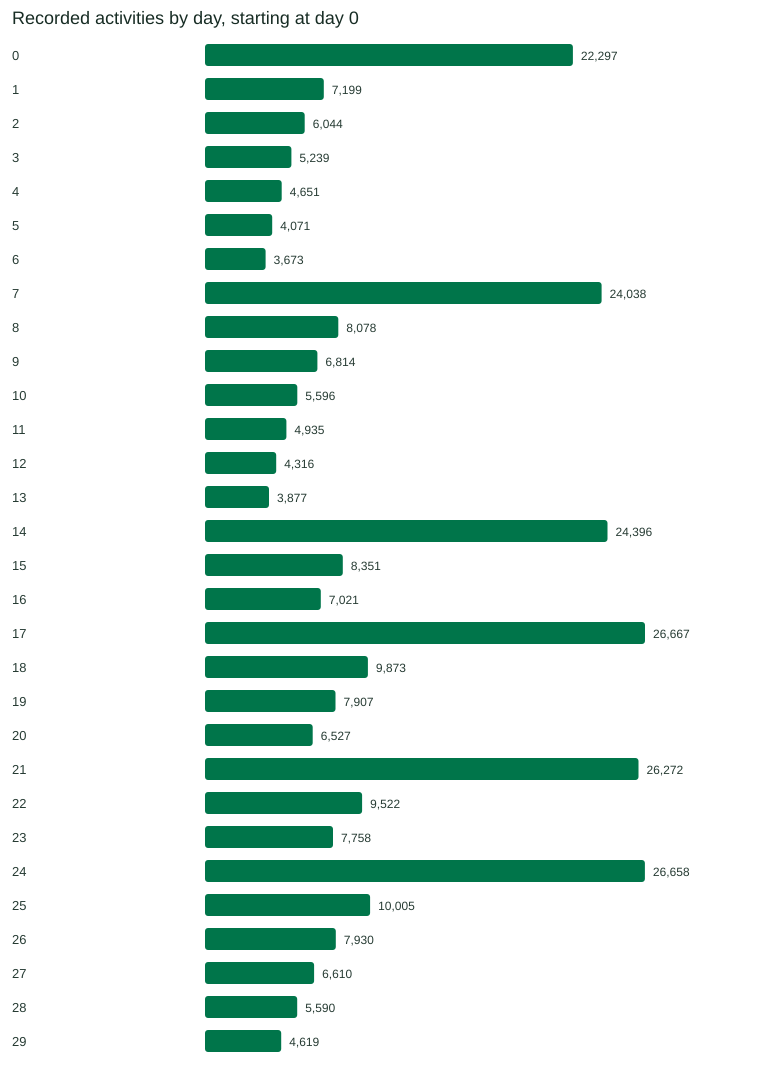

In [9]:
print(f"First event hour: {events['time_hours'].min()}")
print(f"Last event hour: {events['time_hours'].max()}")
print(f"Distinct event timestamps: {events['time_hours'].nunique()}")
observed_times = sorted(events['time_hours'].dropna().unique())
print(f'First twelve recorded timestamps: {observed_times[:12]}')
print('Gaps between consecutive recorded timestamps, in hours:')
display(pd.Series(observed_times).diff().dropna().value_counts().sort_index().rename_axis('gap_hours').to_frame('occurrences'))

daily_activity = events.groupby(['event_day', 'event']).size().unstack(fill_value=0)
display(daily_activity)
show_bar_chart(daily_activity.sum(axis=1), 'Recorded activities by day, starting at day 0')


## 8. Explore purchases separately

Each transaction row records an amount and customer. It has no offer ID. Joining purchases to every active offer could multiply the same purchase, so spend summaries start with the transaction rows alone.


In [10]:
transactions = events.loc[is_transaction, ['source_row', 'customer_id', 'time_hours', 'event_day', 'transaction_amount']].copy()
display(transactions['transaction_amount'].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).round(2).to_frame())
print(f"Recorded purchase amount total: ${transactions['transaction_amount'].sum():,.2f}")
print(f"Zero-amount transactions: {transactions['transaction_amount'].eq(0).sum():,}")
print(f"Negative-amount transactions: {transactions['transaction_amount'].lt(0).sum():,}")

customer_purchases = transactions.groupby('customer_id').agg(
    purchase_count=('source_row', 'size'),
    total_spend=('transaction_amount', 'sum'),
    first_purchase_hour=('time_hours', 'min'),
    last_purchase_hour=('time_hours', 'max'),
)
print(f'Customers with a recorded purchase: {len(customer_purchases):,}')
print(f"Customers without a recorded purchase: {(~customers['customer_id'].isin(customer_purchases.index)).sum():,}")
display(customer_purchases.describe().round(2))


,transaction_amount
count,138953.00
mean,12.78
std,30.25
min,0.05
25%,2.78
50%,8.89
75%,18.07
95%,29.91
99%,40.02
max,1062.28


Recorded purchase amount total: $1,775,451.97
Zero-amount transactions: 0
Negative-amount transactions: 0
Customers with a recorded purchase: 16,578
Customers without a recorded purchase: 422


,purchase_count,total_spend,first_purchase_hour,last_purchase_hour
count,16578.00,16578.00,16578.00,16578.00
mean,8.38,107.10,137.54,628.57
std,5.01,126.39,140.68,82.77
min,1.00,0.05,0.00,12.00
25%,5.00,23.68,36.00,594.00
50%,7.00,72.41,84.00,654.00
75%,11.00,150.94,198.00,690.00
max,36.00,1608.69,714.00,714.00


## 9. Count offer activity without assuming attribution

This table places received, viewed, and completed event counts beside the offer catalog. These are raw counts. The same person can receive the same offer more than once.


In [11]:
offer_activity = (
    events.loc[is_offer_event]
    .groupby(['offer_id', 'event']).size()
    .unstack(fill_value=0)
    .reset_index()
)
offer_activity = offers.merge(offer_activity, on='offer_id', how='left', validate='one_to_one')
display(offer_activity[[
    'offer_label', 'offer_type', 'difficulty', 'reward', 'duration',
    'channel_combination', 'offer received', 'offer viewed', 'offer completed'
]])

receipts_by_pair = (
    events.loc[events['event'].eq('offer received')]
    .groupby(['customer_id', 'offer_id']).size()
)
print(f'Customer–offer pairs receiving that offer more than once: {receipts_by_pair.gt(1).sum():,}')
display(receipts_by_pair.value_counts().sort_index().rename_axis('receipt_count_for_pair').to_frame('customer_offer_pairs'))


,offer_label,offer_type,difficulty,reward,duration,channel_combination,offer received,offer viewed,offer completed
0,O01,bogo,10,10,7,"email, mobile, social",7658,6716,3688
1,O02,bogo,10,10,5,"email, mobile, social, web",7593,7298,3331
2,O03,informational,0,0,4,"email, mobile, web",7617,4144,0
3,O04,bogo,5,5,7,"email, mobile, web",7677,4171,4354
4,O05,discount,20,5,10,"email, web",7668,2663,3420
5,O06,discount,7,3,7,"email, mobile, social, web",7646,7337,5156
6,O07,discount,10,2,10,"email, mobile, social, web",7597,7327,5317
7,O08,informational,0,0,3,"email, mobile, social",7618,6687,0
8,O09,bogo,5,5,5,"email, mobile, social, web",7571,7264,4296
9,O10,discount,10,2,7,"email, mobile, web",7632,4118,4017


Customer–offer pairs receiving that offer more than once: 11,718


,customer_offer_pairs
receipt_count_for_pair,
1,51570
2,10523
3,1124
4,66
5,5


## 10. Follow one customer's activity

We choose the first customer in source order who has all four event types. This gives a readable example of the available records. We join demographics and offer definitions using their IDs.

Rows at the same recorded hour have uncertain within-hour ordering. `source_row` makes the display reproducible and locates the original record. A sequence of rows alone does not establish which offer caused a purchase.


In [12]:
customer_event_types = events.groupby('customer_id')['event'].nunique()
example_customer_id = events.loc[
    events['customer_id'].isin(customer_event_types[customer_event_types.eq(4)].index), 'customer_id'
].iloc[0]

display(customers.loc[customers['customer_id'].eq(example_customer_id),
    ['customer_id', 'age_raw', 'age', 'gender_group', 'income', 'member_since']])

customer_timeline = (
    events.loc[events['customer_id'].eq(example_customer_id)]
    .merge(offers[['offer_id', 'offer_label', 'offer_type', 'duration_hours']],
           on='offer_id', how='left', validate='many_to_one')
    .sort_values(['time_hours', 'source_row'])
)
display(customer_timeline[[
    'source_row', 'time_hours', 'event_day', 'event', 'offer_label',
    'offer_type', 'duration_hours', 'transaction_amount', 'completion_reward'
]])


,customer_id,age_raw,age,gender_group,income,member_since
3,78afa995795e4d85b5d9ceeca43f5fef,75,75,F,100000.0,2017-05-09


,source_row,time_hours,event_day,event,offer_label,offer_type,duration_hours,transaction_amount,completion_reward
0,1,0,0,offer received,O04,bogo,168.0,NaN,NaN
1,15562,6,0,offer viewed,O04,bogo,168.0,NaN,NaN
2,47583,132,5,transaction,NaN,NaN,NaN,19.89,NaN
3,47584,132,5,offer completed,O04,bogo,168.0,NaN,5.0
4,49503,144,6,transaction,NaN,NaN,NaN,17.78,NaN
5,53177,168,7,offer received,O08,informational,72.0,NaN,NaN
6,85292,216,9,offer viewed,O08,informational,72.0,NaN,NaN
7,87135,222,9,transaction,NaN,NaN,NaN,19.67,NaN
8,92105,240,10,transaction,NaN,NaN,NaN,29.72,NaN
9,141567,378,15,transaction,NaN,NaN,NaN,23.93,NaN


## 11. Check offer windows at the observation boundary

A delivery close to the end of the log may still be valid when observation stops. Treating it as an unsuccessful delivery would give it less follow-up time than earlier deliveries.

For this exploratory check, a delivery has a fully observed window only when its expiry is at or before the **last observed event hour**. We will confirm the collection boundary before finalizing the campaign metric.


In [13]:
receipts = (
    events.loc[events['event'].eq('offer received'),
               ['source_row', 'customer_id', 'offer_id', 'time_hours']]
    .merge(offers[['offer_id', 'offer_label', 'offer_type', 'duration_hours']],
           on='offer_id', how='left', validate='many_to_one')
)
receipts['expiry_hour'] = receipts['time_hours'] + receipts['duration_hours']
receipts['full_window_by_last_event'] = receipts['expiry_hour'].le(events['time_hours'].max())
display(receipts.groupby('offer_type').agg(
    deliveries=('source_row', 'size'),
    full_windows=('full_window_by_last_event', 'sum'),
).assign(windows_extending_past_last_event=lambda frame: frame['deliveries'] - frame['full_windows']))


,deliveries,full_windows,windows_extending_past_last_event
offer_type,,,
bogo,30499,27897,2602
discount,30543,22909,7634
informational,15235,15235,0


## 12. Findings and decisions for the next stage

The following findings are generated from the loaded files so they update when the notebook is rerun.


In [14]:
findings = pd.DataFrame([
    ('Dataset size', f'{len(customers):,} customers, {len(offers):,} offers, {len(events):,} event rows'),
    ('Unknown demographic ages', f"{customers['age'].isna().sum():,} customers after treating source age 118 as unknown"),
    ('Payload normalization', 'Received/viewed use offer id; completed uses offer_id'),
    ('Identical repeated events', f'{extra_duplicate_mask.sum():,} rows beyond first occurrences; retained for investigation'),
    ('Repeated offer delivery', f'{receipts_by_pair.gt(1).sum():,} customer–offer pairs have multiple receipts'),
    ('Recorded timeline', f"Hours {events['time_hours'].min()}–{events['time_hours'].max()}"),
    ('Incomplete follow-up', f"{(~receipts['full_window_by_last_event']).sum():,} deliveries expire after the last recorded event"),
], columns=['topic', 'finding'])
display(findings)

assert customers['customer_id'].is_unique, 'Customer IDs must be unique before joining.'
assert offers['offer_id'].is_unique, 'Offer IDs must be unique before joining.'
assert events['customer_id'].isin(customers['customer_id']).all(), 'Investigate unknown customers.'
assert events.loc[is_offer_event, 'offer_id'].isin(offers['offer_id']).all(), 'Investigate unknown offers.'
assert len(events) == len(transcript_raw), 'Normalization must preserve all event rows.'
print('Relationship and row-preservation checks passed.')


,topic,finding
0,Dataset size,"17,000 customers, 10 offers, 306,534 event rows"
1,Unknown demographic ages,"2,175 customers after treating source age 118 as unknown"
2,Payload normalization,Received/viewed use offer id; completed uses offer_id
3,Identical repeated events,397 rows beyond first occurrences; retained for investigation
4,Repeated offer delivery,"11,718 customer–offer pairs have multiple receipts"
5,Recorded timeline,Hours 0–714
6,Incomplete follow-up,"10,236 deliveries expire after the last recorded event"


Relationship and row-preservation checks passed.


**Decisions to resolve before building the offer funnel**

1. Match views and completions to individual receipts using the customer, offer, and validity window. Inspect overlapping deliveries before selecting a matching rule.
2. Decide how to handle events in the same recorded hour. Report this ambiguity when distinguishing completion after view from completion without a prior view.
3. Investigate identical repeated events before deciding whether any should be excluded.
4. Confirm expiry inclusivity and the observation boundary, then restrict comparisons to deliveries with adequate follow-up.
5. Use separate definitions for informational offers. Keep the offer's channel combination attached to its definition.
6. Define purchase cohorts from first observed purchases and show only observable follow-up periods. The recorded membership date can support a separate membership-cohort analysis.
7. Calculate any pre-offer RFM measures using information available before delivery.

**Next deliverable**

A PostgreSQL schema and import process that preserve the raw records and reproduce these checks. The delivery-level funnel and campaign comparisons will build on that model. The later ML ideas remain personalized offer targeting and repeat-purchase prediction.
